<a href="https://colab.research.google.com/github/rahafjafar/smart_water_recommendation_system/blob/main/05_smart_water_recommendation_system.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart Water Advisor — Recommendation System


## Main idea

The recommendation system uses:

1. ML forecasted expected consumption
2. Current sensor/profile data
3. Rule-based advisory logic
4. Visual and user-friendly outputs

System type:

`ML-Assisted Rule-Based Recommendation Engine`

In [ ]:
# ============================================================
# CELL 1 — Import Libraries
# ============================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1200)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ============================================================
# CELL 2 — Load Forecasting Output Dataset
# ============================================================

possible_paths = [
    "../processed_data/optimized_3h_normal_consumption_training_data_with_predictions.csv",
    "processed_data/optimized_3h_normal_consumption_training_data_with_predictions.csv",
    "../processed_data/normal_6h_consumption_training_data_with_predictions.csv",
    "processed_data/normal_6h_consumption_training_data_with_predictions.csv",
    "../processed_data/master_dataset_with_expected_next_6h_normal_consumption.csv",
    "processed_data/master_dataset_with_expected_next_6h_normal_consumption.csv",
    "../processed_data/clean_master_dataset_jordan.csv",
    "processed_data/clean_master_dataset_jordan.csv",
]

DATA_PATH = None

for path in possible_paths:
    if os.path.exists(path):
        DATA_PATH = path
        break

if DATA_PATH is None:
    raise FileNotFoundError("No suitable file found. Please check the processed_data folder.")

df = pd.read_csv(DATA_PATH)

if "timestamp" in df.columns:
    df["timestamp"] = pd.to_datetime(df["timestamp"])

print("Dataset loaded successfully.")
print("Path:", DATA_PATH)
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Path: ../processed_data/optimized_3h_normal_consumption_training_data_with_predictions.csv
Shape: (168264, 98)


,household_id,timestamp,hour,day_of_week,is_weekend,month,season,temperature,building_type,number_of_users,behavior_profile,tank_capacity,num_of_tanks,total_tank_capacity,previous_consumption,actual_consumption,flow_rate,water_level,water_level_change,tank_emptied_flag,sensor_status,anomaly_flag,leak_flag,anomaly_type,rolling_avg_consumption,consumption_pattern_score,time_since_last_usage,day,date,week_of_year,consumption_change,water_level_diff,diff_from_rolling_avg,high_consumption_flag,day_of_week_num,hour_sin,hour_cos,day_sin,day_cos,future_consumption_t_plus_1h,future_anomaly_type_t_plus_1h,future_consumption_t_plus_2h,future_anomaly_type_t_plus_2h,future_consumption_t_plus_3h,future_anomaly_type_t_plus_3h,target_next_3h_total_consumption,future_horizon_all_normal,hour_index_per_household,hours_since_refill,hours_until_refill,days_since_refill,refill_position,is_refill_day,refill_sin,refill_cos,safe_previous_consumption,safe_rolling_avg_7h,safe_rolling_avg_24h,lag_1h,lag_2h,lag_3h,lag_6h,lag_12h,lag_24h,lag_48h,lag_72h,lag_168h,rolling_mean_3h,rolling_std_3h,rolling_mean_6h,rolling_std_6h,rolling_mean_12h,rolling_std_12h,rolling_mean_24h,rolling_std_24h,rolling_mean_48h,rolling_std_48h,rolling_mean_72h,rolling_std_72h,rolling_mean_168h,rolling_std_168h,rolling_min_24h,rolling_max_24h,rolling_min_48h,rolling_max_48h,rolling_min_168h,rolling_max_168h,rolling_sum_3h,rolling_sum_6h,rolling_sum_12h,rolling_sum_24h,momentum_24h,momentum_168h,rolling_momentum_24_168,rolling_range_24h,rolling_range_168h,predicted_3h_consumption,prediction_error_3h
0,H001,2025-01-01,0,Wednesday,0,1,Winter,13.27,Apartment,3,Irregular,1800,2,3600,17.38,17.38,1.14,3582.62,0.0,0,normal,0,0,normal,17.38,0.0,0,1,2025-01-01,1,0.0,0.0,0.0,0,2,0.0,1.0,0.974928,-0.222521,14.57,normal,13.12,normal,20.05,normal,47.74,True,0,0,0,0,0.0,1,0.0,1.0,30.59,30.812857,30.602083,30.59,30.58,30.58,30.58,30.58,30.56,30.51,30.49,30.39,30.92,7.568592,30.81,9.69299,30.774167,10.808268,30.602083,11.248129,30.497396,11.490185,30.488264,11.614382,30.392143,11.691714,12.03,54.03,9.83,57.59,6.74,63.27,92.74,184.75,368.705,731.62,0.08,0.24,-0.199792,41.57,56.09,52.060530,-4.320530
1,H002,2025-01-01,0,Wednesday,0,1,Winter,21.05,House,5,Efficient,1800,5,9000,29.09,29.09,1.77,8970.91,0.0,0,normal,0,0,normal,29.09,0.0,0,1,2025-01-01,1,0.0,0.0,0.0,0,2,0.0,1.0,0.974928,-0.222521,25.94,normal,26.05,normal,25.70,normal,77.69,True,0,0,0,0,0.0,1,0.0,1.0,30.59,30.812857,30.602083,30.59,30.58,30.58,30.58,30.58,30.56,30.51,30.49,30.39,30.92,7.568592,30.81,9.69299,30.774167,10.808268,30.602083,11.248129,30.497396,11.490185,30.488264,11.614382,30.392143,11.691714,12.03,54.03,9.83,57.59,6.74,63.27,92.74,184.75,368.705,731.62,0.08,0.24,-0.199792,41.57,56.09,90.691436,-13.001436
2,H005,2025-01-01,0,Wednesday,0,1,Winter,12.62,Apartment,5,Efficient,1800,2,3600,7.49,7.49,0.63,3592.51,0.0,0,normal,0,0,normal,7.49,0.0,0,1,2025-01-01,1,0.0,0.0,0.0,0,2,0.0,1.0,0.974928,-0.222521,7.64,normal,6.43,normal,10.80,normal,24.87,True,0,0,0,0,0.0,1,0.0,1.0,30.59,30.812857,30.602083,30.59,30.58,30.58,30.58,30.58,30.56,30.51,30.49,30.39,30.92,7.568592,30.81,9.69299,30.774167,10.808268,30.602083,11.248129,30.497396,11.490185,30.488264,11.614382,30.392143,11.691714,12.03,54.03,9.83,57.59,6.74,63.27,92.74,184.75,368.705,731.62,0.08,0.24,-0.199792,41.57,56.09,60.564360,-35.694360
3,H007,2025-01-01,0,Wednesday,0,1,Winter,12.27,Apartment,2,Normal,1800,2,3600,1.98,1.98,0.17,3598.02,0.0,0,normal,0,0,normal,1.98,0.0,1,1,2025-01-01,1,0.0,0.0,0.0,0,2,0.0,1.0,0.974928,-0.222521,14.41,normal,14.14,normal,8.07,normal,36.62,True,0,0,0,0,0.0,1,0.0,1.0,30.59,30.812857,30.602083,30.59,30.58,30.58,30.58,30.58,30.56,30.51,30.49,30.39,30.92,7.568592,30.81,9.69299,30.774167,10.808268,30.602083,11.248129,30.497396,11.490185,30.488264,11.614382,30.392143,11.691714,12.03,54.03,9.83,57.59,6.74,63.27,92.74,184.75,368.705,731.62,0.08,0.24,-0.199792,41.57,56.09,41.211021,-4.591021
4,H008,2025-01-01,0,Wednesday,0,1,Winter,13.38,Apartment,3,Norm

In [ ]:
# ============================================================
# CELL 3 — Standardize Prediction and Target Columns
# ============================================================

prediction_candidates = [
    "predicted_3h_consumption",
    "expected_next_3h_normal_consumption",
    "predicted_6h_consumption",
    "expected_next_6h_normal_consumption",
    "expected_normal_consumption",
    "predicted_consumption_optimized"
]

target_candidates = [
    "target_next_3h_total_consumption",
    "target_next_6h_total_consumption",
    "actual_consumption"
]

prediction_col = None
target_col = None

for col in prediction_candidates:
    if col in df.columns:
        prediction_col = col
        break

for col in target_candidates:
    if col in df.columns:
        target_col = col
        break

if prediction_col is None:
    print("No prediction column found. Using rolling/actual fallback for demonstration.")
    if "rolling_mean_168h" in df.columns:
        prediction_col = "rolling_mean_168h"
    elif "rolling_avg_consumption" in df.columns:
        prediction_col = "rolling_avg_consumption"
    else:
        prediction_col = "actual_consumption"

if target_col is None:
    target_col = "actual_consumption"

if "3h" in prediction_col or "3h" in target_col:
    FORECAST_HORIZON = 3
elif "6h" in prediction_col or "6h" in target_col:
    FORECAST_HORIZON = 6
else:
    FORECAST_HORIZON = 3

df["expected_consumption"] = pd.to_numeric(df[prediction_col], errors="coerce")
df["actual_reference_consumption"] = pd.to_numeric(df[target_col], errors="coerce")

df = df.dropna(subset=["expected_consumption"]).copy()

print("Prediction column:", prediction_col)
print("Reference column:", target_col)
print("Forecast horizon:", FORECAST_HORIZON, "hour(s)")

display(df[["household_id", "timestamp", "expected_consumption", "actual_reference_consumption"]].head())

Prediction column: predicted_3h_consumption
Reference column: target_next_3h_total_consumption
Forecast horizon: 3 hour(s)


,household_id,timestamp,expected_consumption,actual_reference_consumption
0,H001,2025-01-01,52.060530,47.74
1,H002,2025-01-01,90.691436,77.69
2,H005,2025-01-01,60.564360,24.87
3,H007,2025-01-01,41.211021,36.62
4,H008,2025-01-01,52.205487,28.42


## Sensor/Profile Data

In the real app, this information should come from:

- Sensor token
- Household profile database
- Water level sensor
- Temperature API/sensor
- Refill schedule logic

For notebook testing, we simulate this from available dataset columns.

In [ ]:
# ============================================================
# CELL 4 — Prepare Sensor/Profile Fields
# ============================================================

defaults = {
    "water_level": np.nan,
    "tank_capacity": 1800,
    "num_of_tanks": 1,
    "total_tank_capacity": np.nan,
    "number_of_users": 3,
    "temperature": 25,
    "hour": 12,
    "is_weekend": 0,
    "building_type": "Apartment",
    "behavior_profile": "Normal",
    "hours_until_refill": 72,
    "hours_since_refill": 96,
}

for col, value in defaults.items():
    if col not in df.columns:
        df[col] = value

if df["total_tank_capacity"].isnull().all():
    df["total_tank_capacity"] = df["tank_capacity"] * df["num_of_tanks"]

df["water_level"] = df["water_level"].fillna(df["total_tank_capacity"] * 0.5)

df["water_level"] = df["water_level"].clip(lower=0)
df["total_tank_capacity"] = df["total_tank_capacity"].clip(lower=1)

df["tank_level_pct"] = (
    df["water_level"] / df["total_tank_capacity"] * 100
).clip(0, 100)

df["projected_water_level"] = (
    df["water_level"] - df["expected_consumption"]
).clip(lower=0)

df["projected_tank_level_pct"] = (
    df["projected_water_level"] / df["total_tank_capacity"] * 100
).clip(0, 100)

print("Sensor/profile features prepared.")

display(df[[
    "household_id",
    "timestamp",
    "expected_consumption",
    "water_level",
    "total_tank_capacity",
    "tank_level_pct",
    "projected_tank_level_pct",
    "hours_until_refill"
]].head())

Sensor/profile features prepared.


,household_id,timestamp,expected_consumption,water_level,total_tank_capacity,tank_level_pct,projected_tank_level_pct,hours_until_refill
0,H001,2025-01-01,52.060530,3582.62,3600,99.517222,98.071096,0
1,H002,2025-01-01,90.691436,8970.91,9000,99.676778,98.669095,0
2,H005,2025-01-01,60.564360,3592.51,3600,99.791944,98.109601,0
3,H007,2025-01-01,41.211021,3598.02,3600,99.945000,98.800249,0
4,H008,2025-01-01,52.205487,3592.45,3600,99.790278,98.340125,0


## Smart Water Score

The system creates a score from 0 to 100.

Higher score = safer and more efficient water situation.

In [ ]:
# ============================================================
# CELL 5 — Create Risk Score and Water Saving Score
# ============================================================

df["consumption_share_of_tank_pct"] = (
    df["expected_consumption"] / df["total_tank_capacity"] * 100
).clip(0, 100)

df["refill_pressure_pct"] = (
    df["hours_until_refill"] / 168 * 100
).clip(0, 100)

df["temperature_pressure_pct"] = (
    ((df["temperature"] - 30) / 15) * 100
).clip(0, 100)

df["weekend_pressure_pct"] = df["is_weekend"].astype(int) * 10

df["risk_score"] = (
    0.35 * df["consumption_share_of_tank_pct"] +
    0.30 * (100 - df["projected_tank_level_pct"]) +
    0.20 * df["refill_pressure_pct"] +
    0.10 * df["temperature_pressure_pct"] +
    0.05 * df["weekend_pressure_pct"]
).clip(0, 100)

df["water_saving_score"] = (100 - df["risk_score"]).clip(0, 100)

print("Risk score and water saving score created.")

display(df[[
    "expected_consumption",
    "tank_level_pct",
    "projected_tank_level_pct",
    "risk_score",
    "water_saving_score"
]].head())

Risk score and water saving score created.


,expected_consumption,tank_level_pct,projected_tank_level_pct,risk_score,water_saving_score
0,52.060530,99.517222,98.071096,1.084815,98.915185
1,90.691436,99.676778,98.669095,0.751960,99.248040
2,60.564360,99.791944,98.109601,1.155940,98.844060
3,41.211021,99.945000,98.800249,0.760588,99.239412
4,52.205487,99.790278,98.340125,1.005516,98.994484


In [ ]:
# ============================================================
# CELL 6 — Recommendation Engine Rules
# ============================================================

def generate_recommendation(row):
    projected_pct = row["projected_tank_level_pct"]
    score = row["water_saving_score"]
    hours_until_refill = row["hours_until_refill"]
    temperature = row["temperature"]
    is_weekend = row["is_weekend"]
    horizon = FORECAST_HORIZON

    if projected_pct < 10:
        return pd.Series({
            "risk_level": "Critical",
            "recommendation_category": "Critical tank risk",
            "priority": "Urgent",
            "icon": "🔴",
            "main_message": f"Your tank may become critically low within the next {horizon} hours.",
            "suggested_action": "Use water only for essential needs and avoid laundry, cleaning, or garden usage until refill."
        })

    if projected_pct < 25 and hours_until_refill > 36:
        return pd.Series({
            "risk_level": "High",
            "recommendation_category": "Scarcity preparation",
            "priority": "High",
            "icon": "🚰",
            "main_message": "Your water level may not be enough until the next refill cycle.",
            "suggested_action": "Reduce non-essential consumption and prioritize drinking, cooking, and hygiene usage."
        })

    if score < 45:
        return pd.Series({
            "risk_level": "High",
            "recommendation_category": "High consumption warning",
            "priority": "High",
            "icon": "⚠️",
            "main_message": f"Expected usage is high for the next {horizon} hours.",
            "suggested_action": "Delay laundry, reduce long showers, and monitor taps during this period."
        })

    if score < 65:
        return pd.Series({
            "risk_level": "Medium",
            "recommendation_category": "Usage watch",
            "priority": "Medium",
            "icon": "🟡",
            "main_message": "Your expected usage is slightly above the ideal range.",
            "suggested_action": "Try reducing optional usage and keep an eye on the tank level."
        })

    if is_weekend == 1 or temperature >= 32:
        return pd.Series({
            "risk_level": "Low",
            "recommendation_category": "Preventive saving tip",
            "priority": "Low",
            "icon": "💧",
            "main_message": "Your usage looks acceptable, but demand may rise due to weekend or hot weather.",
            "suggested_action": "Plan water-heavy activities carefully and avoid unnecessary usage."
        })

    if score >= 85:
        return pd.Series({
            "risk_level": "Excellent",
            "recommendation_category": "Efficient usage",
            "priority": "Info",
            "icon": "🌿",
            "main_message": f"Great job! Your expected usage is efficient for the next {horizon} hours.",
            "suggested_action": "Keep your current usage pattern."
        })

    return pd.Series({
        "risk_level": "Normal",
        "recommendation_category": "Normal usage",
        "priority": "Info",
        "icon": "✅",
        "main_message": "Your expected consumption is within a normal range.",
        "suggested_action": "No urgent action is needed."
    })


recommendations = df.apply(generate_recommendation, axis=1)
df = pd.concat([df, recommendations], axis=1)

print("Recommendations generated successfully.")

display(df[[
    "household_id",
    "timestamp",
    "expected_consumption",
    "tank_level_pct",
    "projected_tank_level_pct",
    "water_saving_score",
    "risk_level",
    "recommendation_category",
    "priority",
    "main_message",
    "suggested_action"
]].head(10))

Recommendations generated successfully.


,household_id,timestamp,expected_consumption,tank_level_pct,projected_tank_level_pct,water_saving_score,risk_level,recommendation_category,priority,main_message,suggested_action
0,H001,2025-01-01,52.060530,99.517222,98.071096,98.915185,Excellent,Efficient usage,Info,Great job! Your expected usage is efficient fo...,Keep your current usage pattern.
1,H002,2025-01-01,90.691436,99.676778,98.669095,99.248040,Excellent,Efficient usage,Info,Great job! Your expected usage is efficient fo...,Keep your current usage pattern.
2,H005,2025-01-01,60.564360,99.791944,98.109601,98.844060,Excellent,Efficient usage,Info,Great job! Your expected usage is efficient fo...,Keep your current usage pattern.
3,H007,2025-01-01,41.211021,99.945000,98.800249,99.239412,Excellent,Efficient usage,Info,Great job! Your expected usage is efficient fo...,Keep your current usage pattern.
4,H008,2025-01-01,52.205487,99.790278,98.340125,98.994484,Excellent,Efficient usage,Info,Great job! Your expected usage is efficient fo...,Keep your current usage pattern.
5,H009,2025-01-01,71.761282,99.425556,98.428871,99.179822,Excellent,Efficient usage,Info,Great job! Your expected usage is efficient fo...,Keep your current usage pattern.
6,H010,2025-01-01,84.847439,99.824333,98.881584,99.334513,Excellent,Efficient usage,Info,Great job! Your expected usage is efficient fo...,Keep your current usage pattern.
7,H011,2025-01-01,117.391413,99.548611,98.461654,99.158061,Excellent,Efficient usage,Info,Great job! Your expected usage is efficient fo...,Keep your current usage pattern.
8,H012,2025-01-01,52.969609,99.811944,98.340566,98.987188,Excellent,Efficient usage,Info,Great job! Your expected usage is efficient fo...,Keep your current usage pattern.
9,H013,2025-01-01,73.405095,99.390556,98.371040,99.154482,Excellent,Efficient usage,Info,Great job! Your expected usage is efficient fo...,Keep your current usage pattern.


In [ ]:
# ============================================================
# CELL 7 — Preview One User-Friendly Recommendation Card
# ============================================================

sample = df.sample(1, random_state=42).iloc[0]

print("=" * 80)
print("SMART WATER ADVISOR")
print("=" * 80)
print(f"Household: {sample['household_id']}")
print(f"Timestamp: {sample['timestamp']}")
print("-" * 80)
print(f"{sample['icon']} Risk Level: {sample['risk_level']}")
print(f"Category: {sample['recommendation_category']}")
print(f"Priority: {sample['priority']}")
print("-" * 80)
print(f"Expected Consumption: {sample['expected_consumption']:.2f} liters / next {FORECAST_HORIZON} hours")
print(f"Current Tank Level: {sample['tank_level_pct']:.1f}%")
print(f"Projected Tank Level: {sample['projected_tank_level_pct']:.1f}%")
print(f"Water Saving Score: {sample['water_saving_score']:.1f}/100")
print("-" * 80)
print("Message:")
print(sample["main_message"])
print()
print("Suggested Action:")
print(sample["suggested_action"])
print("=" * 80)

SMART WATER ADVISOR
Household: H032
Timestamp: 2025-04-07 00:00:00
--------------------------------------------------------------------------------
🌿 Risk Level: Excellent
Category: Efficient usage
Priority: Info
--------------------------------------------------------------------------------
Expected Consumption: 75.65 liters / next 3 hours
Current Tank Level: 72.9%
Projected Tank Level: 71.9%
Water Saving Score: 90.6/100
--------------------------------------------------------------------------------
Message:
Great job! Your expected usage is efficient for the next 3 hours.

Suggested Action:
Keep your current usage pattern.


## Recommendation Evaluation

Because this is a rule-based recommendation engine, we evaluate it using consistency metrics instead of classification accuracy.

In [ ]:
# ============================================================
# CELL 8 — Evaluation Metrics
# ============================================================

coverage = df["recommendation_category"].notnull().mean() * 100

recommendation_distribution = (
    df["recommendation_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .reset_index()
)

recommendation_distribution.columns = ["recommendation_category", "percentage"]

risk_summary = (
    df.groupby("risk_level")
    .agg(
        records=("risk_level", "count"),
        avg_risk_score=("risk_score", "mean"),
        avg_water_saving_score=("water_saving_score", "mean"),
        avg_expected_consumption=("expected_consumption", "mean"),
        avg_projected_tank_pct=("projected_tank_level_pct", "mean")
    )
    .round(2)
    .sort_values(by="avg_risk_score", ascending=False)
)

critical_high_df = df[df["risk_level"].isin(["Critical", "High"])]

if len(critical_high_df) > 0:
    high_risk_low_tank_rate = (critical_high_df["projected_tank_level_pct"] < 30).mean() * 100
else:
    high_risk_low_tank_rate = 0

print("=" * 80)
print("RECOMMENDATION SYSTEM EVALUATION SUMMARY")
print("=" * 80)
print(f"Total records evaluated: {len(df)}")
print(f"Recommendation coverage: {coverage:.2f}%")
print(f"High/Critical low-tank consistency: {high_risk_low_tank_rate:.2f}%")

print("\nRecommendation Distribution:")
display(recommendation_distribution)

print("\nRisk Level Summary:")
display(risk_summary)

RECOMMENDATION SYSTEM EVALUATION SUMMARY
Total records evaluated: 168264
Recommendation coverage: 100.00%
High/Critical low-tank consistency: 100.00%

Recommendation Distribution:


,recommendation_category,percentage
0,Normal usage,47.34
1,Preventive saving tip,25.26
2,Scarcity preparation,8.60
3,Efficient usage,7.92
4,Usage watch,6.40
5,Critical tank risk,4.49



Risk Level Summary:


,records,avg_risk_score,avg_water_saving_score,avg_expected_consumption,avg_projected_tank_pct
risk_level,,,,,
Critical,7549,39.99,60.01,136.69,5.36
High,14464,38.12,61.88,118.72,17.98
Medium,10769,38.07,61.93,103.30,35.68
Normal,79658,24.32,75.68,97.66,55.18
Low,42505,19.29,80.71,112.68,73.83
Excellent,13319,11.68,88.32,90.77,73.62


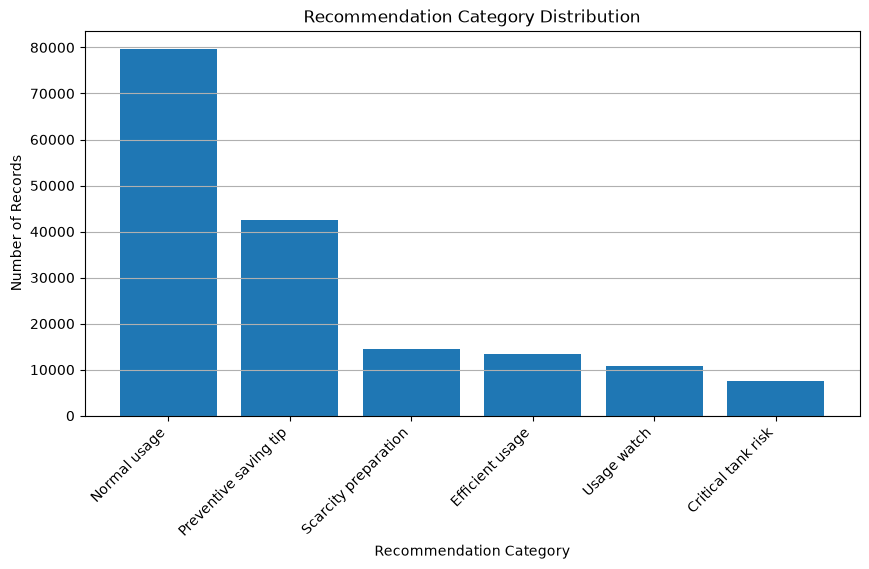

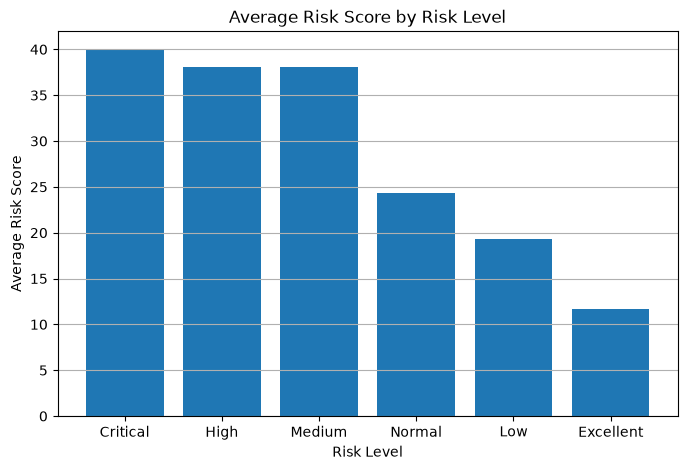

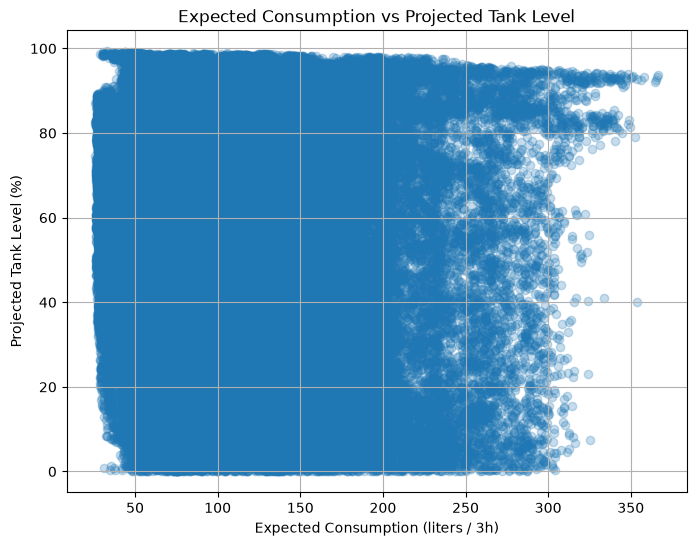

In [ ]:
# ============================================================
# CELL 9 — Visualizations
# ============================================================

plt.figure(figsize=(10, 5))
counts = df["recommendation_category"].value_counts()
plt.bar(counts.index, counts.values)
plt.title("Recommendation Category Distribution")
plt.xlabel("Recommendation Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.show()

risk_plot = df.groupby("risk_level")["risk_score"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(risk_plot.index, risk_plot.values)
plt.title("Average Risk Score by Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Average Risk Score")
plt.grid(axis="y")
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(df["expected_consumption"], df["projected_tank_level_pct"], alpha=0.25)
plt.title("Expected Consumption vs Projected Tank Level")
plt.xlabel(f"Expected Consumption (liters / {FORECAST_HORIZON}h)")
plt.ylabel("Projected Tank Level (%)")
plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# CELL 10 — Streamlit-Ready Recommendation Function
# ============================================================

def smart_water_advisor(sensor_packet, expected_consumption, forecast_horizon=3):
    water_level = sensor_packet.get("water_level", 0)
    total_tank_capacity = max(sensor_packet.get("total_tank_capacity", 1), 1)
    hours_until_refill = sensor_packet.get("hours_until_refill", 72)
    temperature = sensor_packet.get("temperature", 25)
    is_weekend = sensor_packet.get("is_weekend", 0)
    users = sensor_packet.get("number_of_users", 3)
    building_type = sensor_packet.get("building_type", "Apartment")
    behavior_profile = sensor_packet.get("behavior_profile", "Normal")

    tank_level_pct = np.clip(water_level / total_tank_capacity * 100, 0, 100)
    projected_water_level = max(water_level - expected_consumption, 0)
    projected_tank_level_pct = np.clip(projected_water_level / total_tank_capacity * 100, 0, 100)

    consumption_share_of_tank_pct = np.clip(expected_consumption / total_tank_capacity * 100, 0, 100)
    refill_pressure_pct = np.clip(hours_until_refill / 168 * 100, 0, 100)
    temperature_pressure_pct = np.clip(((temperature - 30) / 15) * 100, 0, 100)
    weekend_pressure_pct = int(is_weekend) * 10

    risk_score = np.clip(
        0.35 * consumption_share_of_tank_pct +
        0.30 * (100 - projected_tank_level_pct) +
        0.20 * refill_pressure_pct +
        0.10 * temperature_pressure_pct +
        0.05 * weekend_pressure_pct,
        0,
        100
    )

    water_saving_score = np.clip(100 - risk_score, 0, 100)

    temp_row = pd.Series({
        "expected_consumption": expected_consumption,
        "tank_level_pct": tank_level_pct,
        "projected_tank_level_pct": projected_tank_level_pct,
        "water_saving_score": water_saving_score,
        "risk_score": risk_score,
        "hours_until_refill": hours_until_refill,
        "temperature": temperature,
        "is_weekend": is_weekend,
        "number_of_users": users,
        "building_type": building_type,
        "behavior_profile": behavior_profile
    })

    recommendation = generate_recommendation(temp_row)

    return {
        "expected_consumption": round(expected_consumption, 2),
        "tank_level_pct": round(tank_level_pct, 2),
        "projected_tank_level_pct": round(projected_tank_level_pct, 2),
        "risk_score": round(risk_score, 2),
        "water_saving_score": round(water_saving_score, 2),
        "risk_level": recommendation["risk_level"],
        "recommendation_category": recommendation["recommendation_category"],
        "priority": recommendation["priority"],
        "icon": recommendation["icon"],
        "main_message": recommendation["main_message"],
        "suggested_action": recommendation["suggested_action"],
        "forecast_horizon": forecast_horizon
    }


example_sensor_packet = {
    "water_level": 850,
    "total_tank_capacity": 3600,
    "hours_until_refill": 72,
    "temperature": 34,
    "is_weekend": 1,
    "number_of_users": 4,
    "building_type": "House",
    "behavior_profile": "Normal"
}

smart_water_advisor(
    sensor_packet=example_sensor_packet,
    expected_consumption=320,
    forecast_horizon=3
)

{'expected_consumption': 320,
 'tank_level_pct': np.float64(23.61),
 'projected_tank_level_pct': np.float64(14.72),
 'risk_score': np.float64(40.43),
 'water_saving_score': np.float64(59.57),
 'risk_level': 'High',
 'recommendation_category': 'Scarcity preparation',
 'priority': 'High',
 'icon': '🚰',
 'main_message': 'Your water level may not be enough until the next refill cycle.',
 'suggested_action': 'Reduce non-essential consumption and prioritize drinking, cooking, and hygiene usage.',
 'forecast_horizon': 3}

In [ ]:
# ============================================================
# CELL 11 — Save Outputs
# ============================================================

os.makedirs("../processed_data", exist_ok=True)
os.makedirs("../reports", exist_ok=True)

output_path = f"../processed_data/smart_water_recommendations_{FORECAST_HORIZON}h.csv"
report_path = f"../reports/smart_water_recommendation_summary_{FORECAST_HORIZON}h.csv"

df.to_csv(output_path, index=False)
risk_summary.to_csv(report_path)

print("Saved successfully:")
print(output_path)
print(report_path)

Saved successfully:
../processed_data/smart_water_recommendations_3h.csv
../reports/smart_water_recommendation_summary_3h.csv


In [ ]:
# ============================================================
# CELL 12 — Final Summary
# ============================================================

print("=" * 80)
print("SMART WATER ADVISOR SUMMARY")
print("=" * 80)

print("\nSystem Type:")
print("ML-Assisted Rule-Based Recommendation System")

print("\nForecast horizon:")
print(f"Next {FORECAST_HORIZON} hours")

print("\nMain Outputs:")
print("- Risk level")
print("- Water saving score")
print("- Projected tank level")
print("- Personalized recommendation")
print("- Suggested action")

print("\nEvaluation:")
print(f"Coverage: {coverage:.2f}%")
print(f"High/Critical low-tank consistency: {high_risk_low_tank_rate:.2f}%")

print("\nRecommendation distribution:")
display(recommendation_distribution)

print("\nRisk summary:")
display(risk_summary)

SMART WATER ADVISOR SUMMARY

System Type:
ML-Assisted Rule-Based Recommendation System

Forecast horizon:
Next 3 hours

Main Outputs:
- Risk level
- Water saving score
- Projected tank level
- Personalized recommendation
- Suggested action

Evaluation:
Coverage: 100.00%
High/Critical low-tank consistency: 100.00%

Recommendation distribution:


,recommendation_category,percentage
0,Normal usage,47.34
1,Preventive saving tip,25.26
2,Scarcity preparation,8.60
3,Efficient usage,7.92
4,Usage watch,6.40
5,Critical tank risk,4.49



Risk summary:


,records,avg_risk_score,avg_water_saving_score,avg_expected_consumption,avg_projected_tank_pct
risk_level,,,,,
Critical,7549,39.99,60.01,136.69,5.36
High,14464,38.12,61.88,118.72,17.98
Medium,10769,38.07,61.93,103.30,35.68
Normal,79658,24.32,75.68,97.66,55.18
Low,42505,19.29,80.71,112.68,73.83
Excellent,13319,11.68,88.32,90.77,73.62


In [ ]:
# ============================================================
# SAMPLE CASE — MODEL PREDICTION + RECOMMENDATION
# ============================================================

import joblib
import pandas as pd
import numpy as np

# Choose model path based on your best 3-hour model
MODEL_PATH = "../models/optimized_3h_normal_consumption_forecasting_model.pkl"

# Load consumption forecasting model
consumption_model = joblib.load(MODEL_PATH)

# Take one random sample from the data
sample = df.sample(1, random_state=7).copy()

print("=" * 80)
print("SENSOR / PROFILE DATA USED FOR RECOMMENDATION")
print("=" * 80)

important_cols = [
    "household_id",
    "timestamp",
    "building_type",
    "behavior_profile",
    "number_of_users",
    "num_of_tanks",
    "total_tank_capacity",
    "water_level",
    "tank_level_pct",
    "temperature",
    "is_weekend",
    "hours_until_refill",
    "hours_since_refill"
]

available_cols = [col for col in important_cols if col in sample.columns]
display(sample[available_cols])

# Get model input features automatically
try:
    model_features = consumption_model.feature_names_in_
except:
    model_features = consumption_model.named_steps["preprocessor"].feature_names_in_

# Predict expected consumption using the consumption model
expected_consumption = consumption_model.predict(sample[model_features])[0]

print("=" * 80)
print("CONSUMPTION MODEL PREDICTION")
print("=" * 80)
print(f"Predicted expected consumption: {expected_consumption:.2f} liters / next 3 hours")

# Create sensor packet from the sampled row
sensor_packet = {
    "water_level": float(sample["water_level"].iloc[0]),
    "total_tank_capacity": float(sample["total_tank_capacity"].iloc[0]),
    "hours_until_refill": float(sample["hours_until_refill"].iloc[0]),
    "temperature": float(sample["temperature"].iloc[0]),
    "is_weekend": int(sample["is_weekend"].iloc[0]),
    "number_of_users": int(sample["number_of_users"].iloc[0]),
    "building_type": sample["building_type"].iloc[0],
    "behavior_profile": sample["behavior_profile"].iloc[0],
}

# Generate recommendation
recommendation = smart_water_advisor(
    sensor_packet=sensor_packet,
    expected_consumption=expected_consumption,
    forecast_horizon=3
)

print("=" * 80)
print("SMART WATER ADVISOR RECOMMENDATION")
print("=" * 80)

print(f"{recommendation['icon']} Risk Level: {recommendation['risk_level']}")
print(f"Category: {recommendation['recommendation_category']}")
print(f"Priority: {recommendation['priority']}")

print("-" * 80)
print(f"Expected Consumption: {recommendation['expected_consumption']} liters / next 3 hours")
print(f"Current Tank Level: {recommendation['tank_level_pct']}%")
print(f"Projected Tank Level: {recommendation['projected_tank_level_pct']}%")
print(f"Water Saving Score: {recommendation['water_saving_score']}/100")
print(f"Risk Score: {recommendation['risk_score']}/100")

print("-" * 80)
print("Message:")
print(recommendation["main_message"])

print("\nSuggested Action:")
print(recommendation["suggested_action"])
print("=" * 80)

SENSOR / PROFILE DATA USED FOR RECOMMENDATION


,household_id,timestamp,building_type,behavior_profile,number_of_users,num_of_tanks,total_tank_capacity,water_level,tank_level_pct,temperature,is_weekend,hours_until_refill,hours_since_refill
128642,H003,2025-05-17 14:00:00,Apartment,High_Usage,4,2,3600,3205.4,89.038889,25.22,1,47,121


CONSUMPTION MODEL PREDICTION
Predicted expected consumption: 72.59 liters / next 3 hours
SMART WATER ADVISOR RECOMMENDATION
💧 Risk Level: Low
Category: Preventive saving tip
Priority: Low
--------------------------------------------------------------------------------
Expected Consumption: 72.59 liters / next 3 hours
Current Tank Level: 89.04%
Projected Tank Level: 87.02%
Water Saving Score: 89.31/100
Risk Score: 10.69/100
--------------------------------------------------------------------------------
Message:
Your usage looks acceptable, but demand may rise due to weekend or hot weather.

Suggested Action:
Plan water-heavy activities carefully and avoid unnecessary usage.
